In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [127]:
batch_results = pd.read_csv("../results/batch_results.csv")
batch_results.head()

,x,theta,success,settle_time
0,-0.064178,-171.821902,True,6.63
1,0.049164,-86.915919,True,5.76
2,0.155740,147.092059,True,6.27
3,-0.149244,-72.483995,True,5.70
4,-0.066262,-28.732756,True,6.25


<Axes: xlabel='theta'>

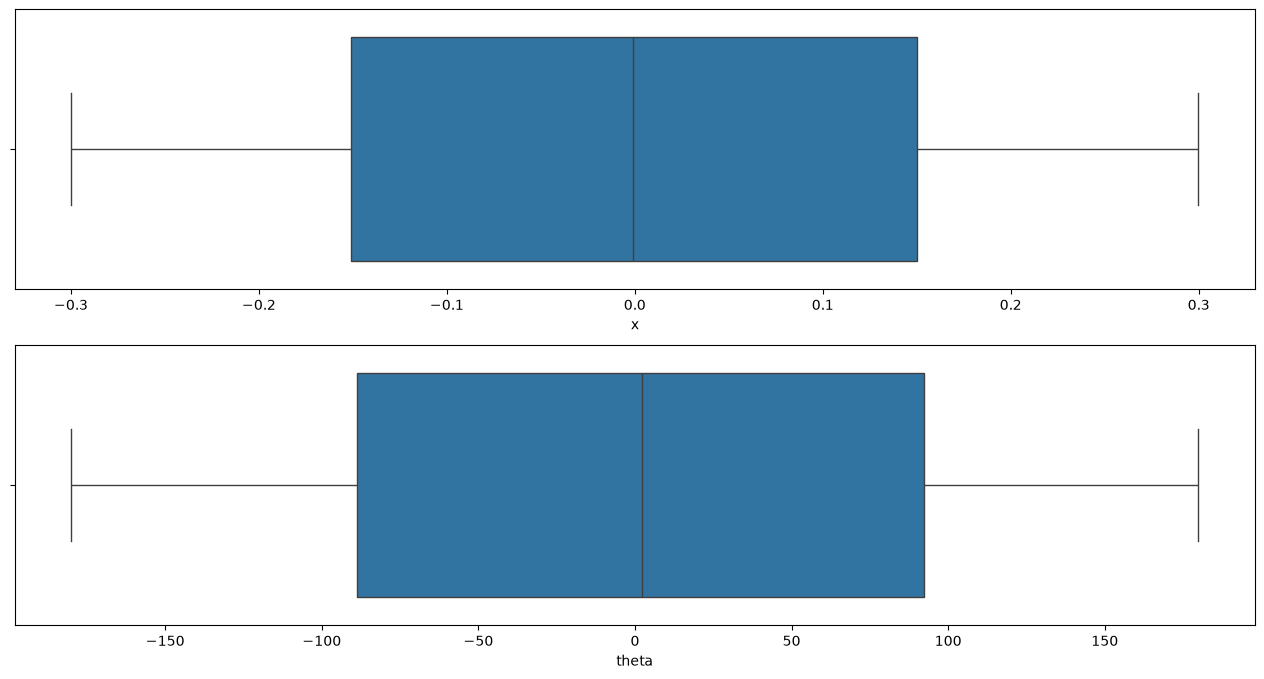

In [128]:
f, axes = plt.subplots(2, 1, figsize=(16, 8))
sb.boxplot(data=batch_results["x"], ax=axes[0], orient="h")
sb.boxplot(data=batch_results["theta"], ax=axes[1], orient="h")

In [129]:
successful_runs = batch_results.loc[batch_results["success"]==True]
successful_runs.head()

,x,theta,success,settle_time
0,-0.064178,-171.821902,True,6.63
1,0.049164,-86.915919,True,5.76
2,0.155740,147.092059,True,6.27
3,-0.149244,-72.483995,True,5.70
4,-0.066262,-28.732756,True,6.25


In [130]:
failed_runs = batch_results.loc[batch_results["success"]==False]
failed_runs.head()

,x,theta,success,settle_time
8914,-0.008693,-17.154201,False,-1.0


In [131]:
len(failed_runs)

1

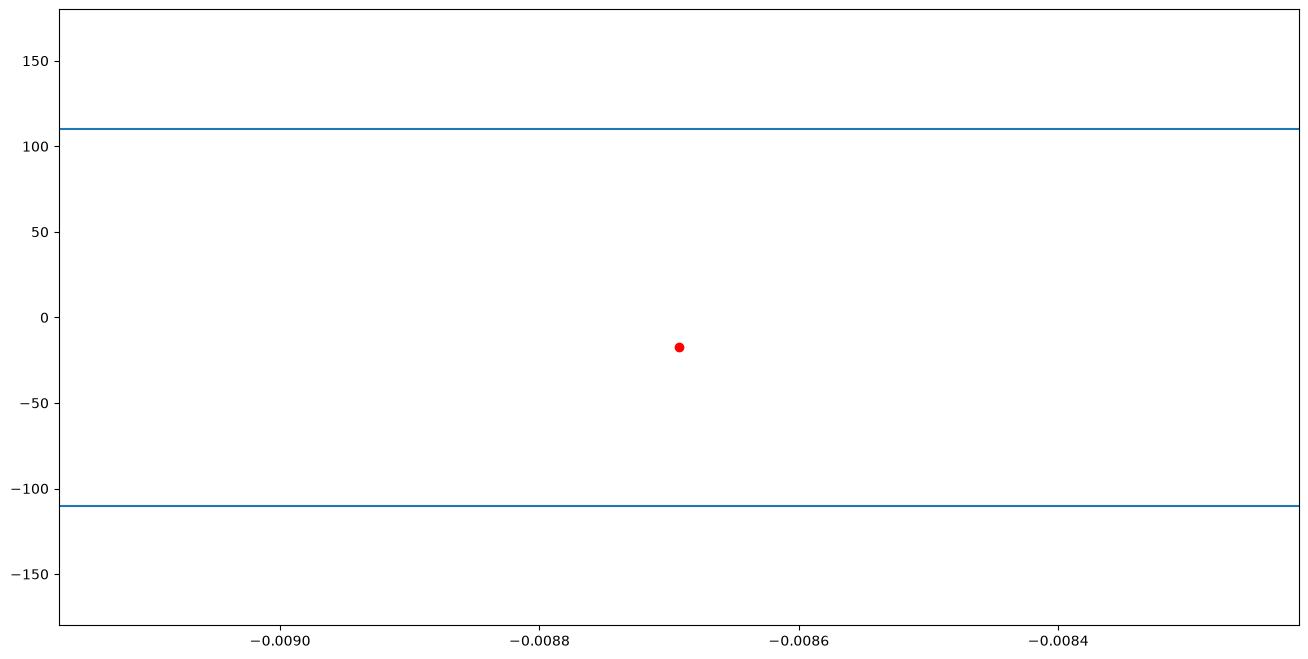

In [132]:
f = plt.figure(figsize=(16, 8))
# plt.scatter(successful_runs["x"], successful_runs["theta"], color="green")
plt.scatter(failed_runs["x"], failed_runs["theta"], color="red")
plt.ylim((-180, 180))
plt.axhline(110)
plt.axhline(-110)

In [133]:
print(max(failed_runs["theta"]))
print(min(failed_runs["theta"]))

-17.154200539287086
-17.154200539287086


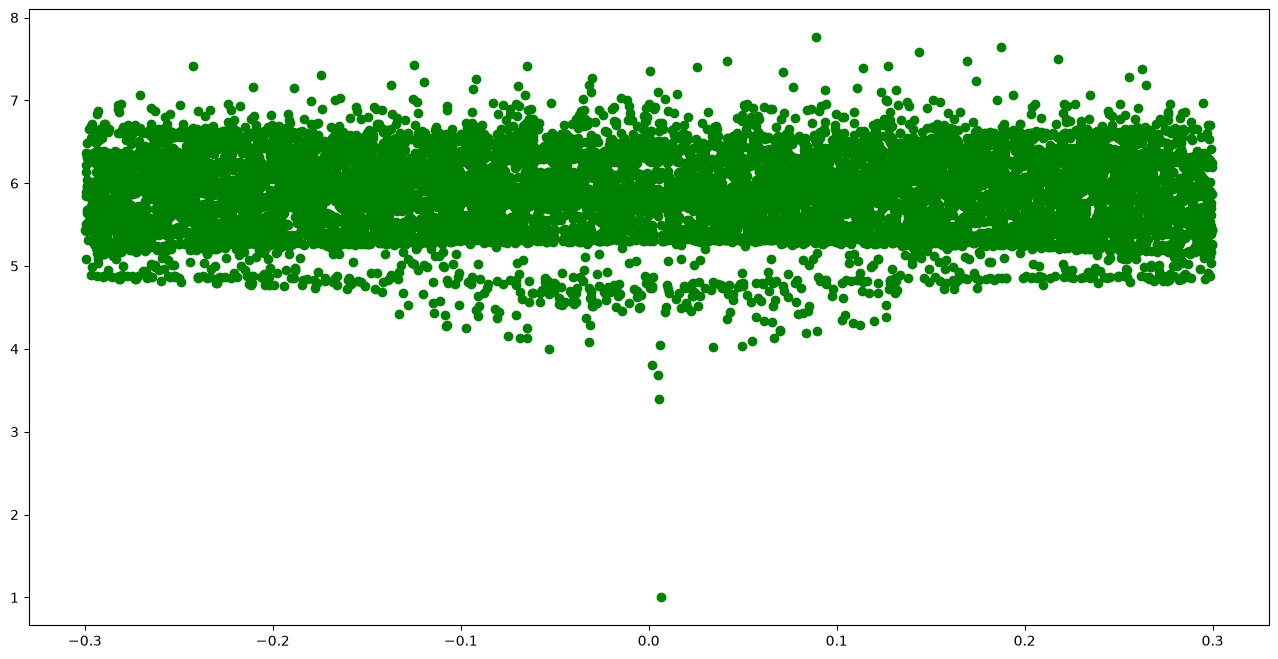

In [134]:
f = plt.figure(figsize=(16, 8))
plt.scatter(successful_runs["x"], successful_runs["settle_time"], color="green")

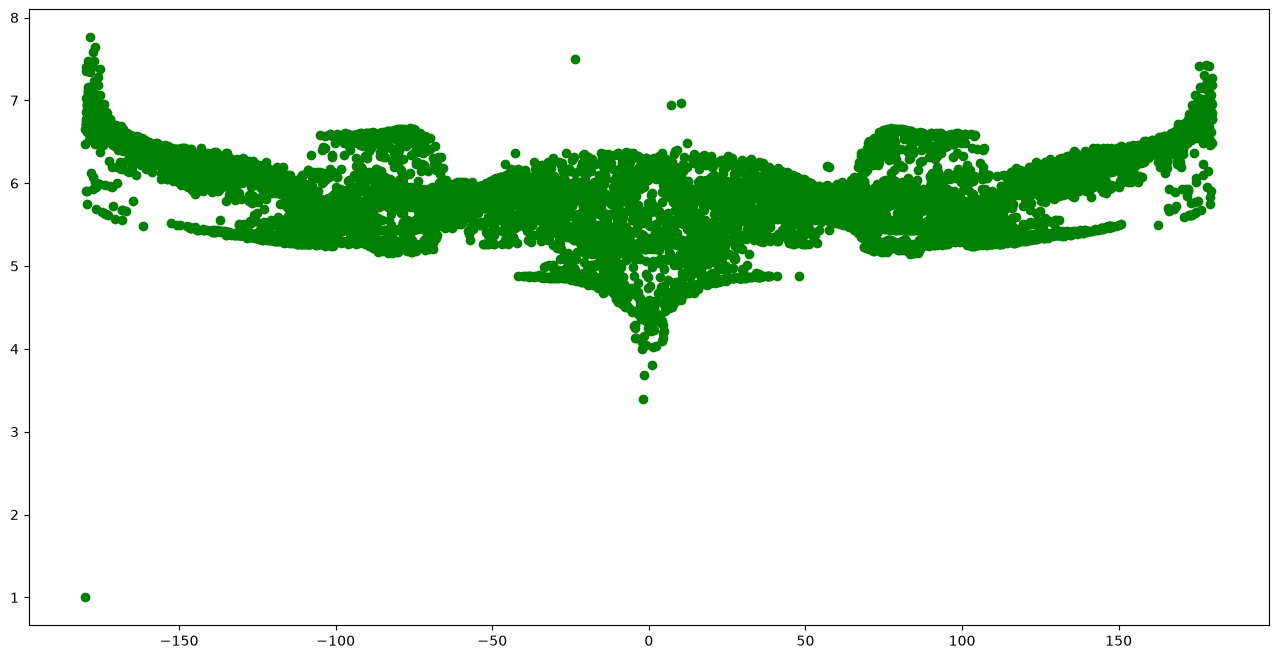

In [135]:
f = plt.figure(figsize=(16, 8))
plt.scatter(successful_runs["theta"], successful_runs["settle_time"], color="green")

<Axes: xlabel='theta', ylabel='success'>

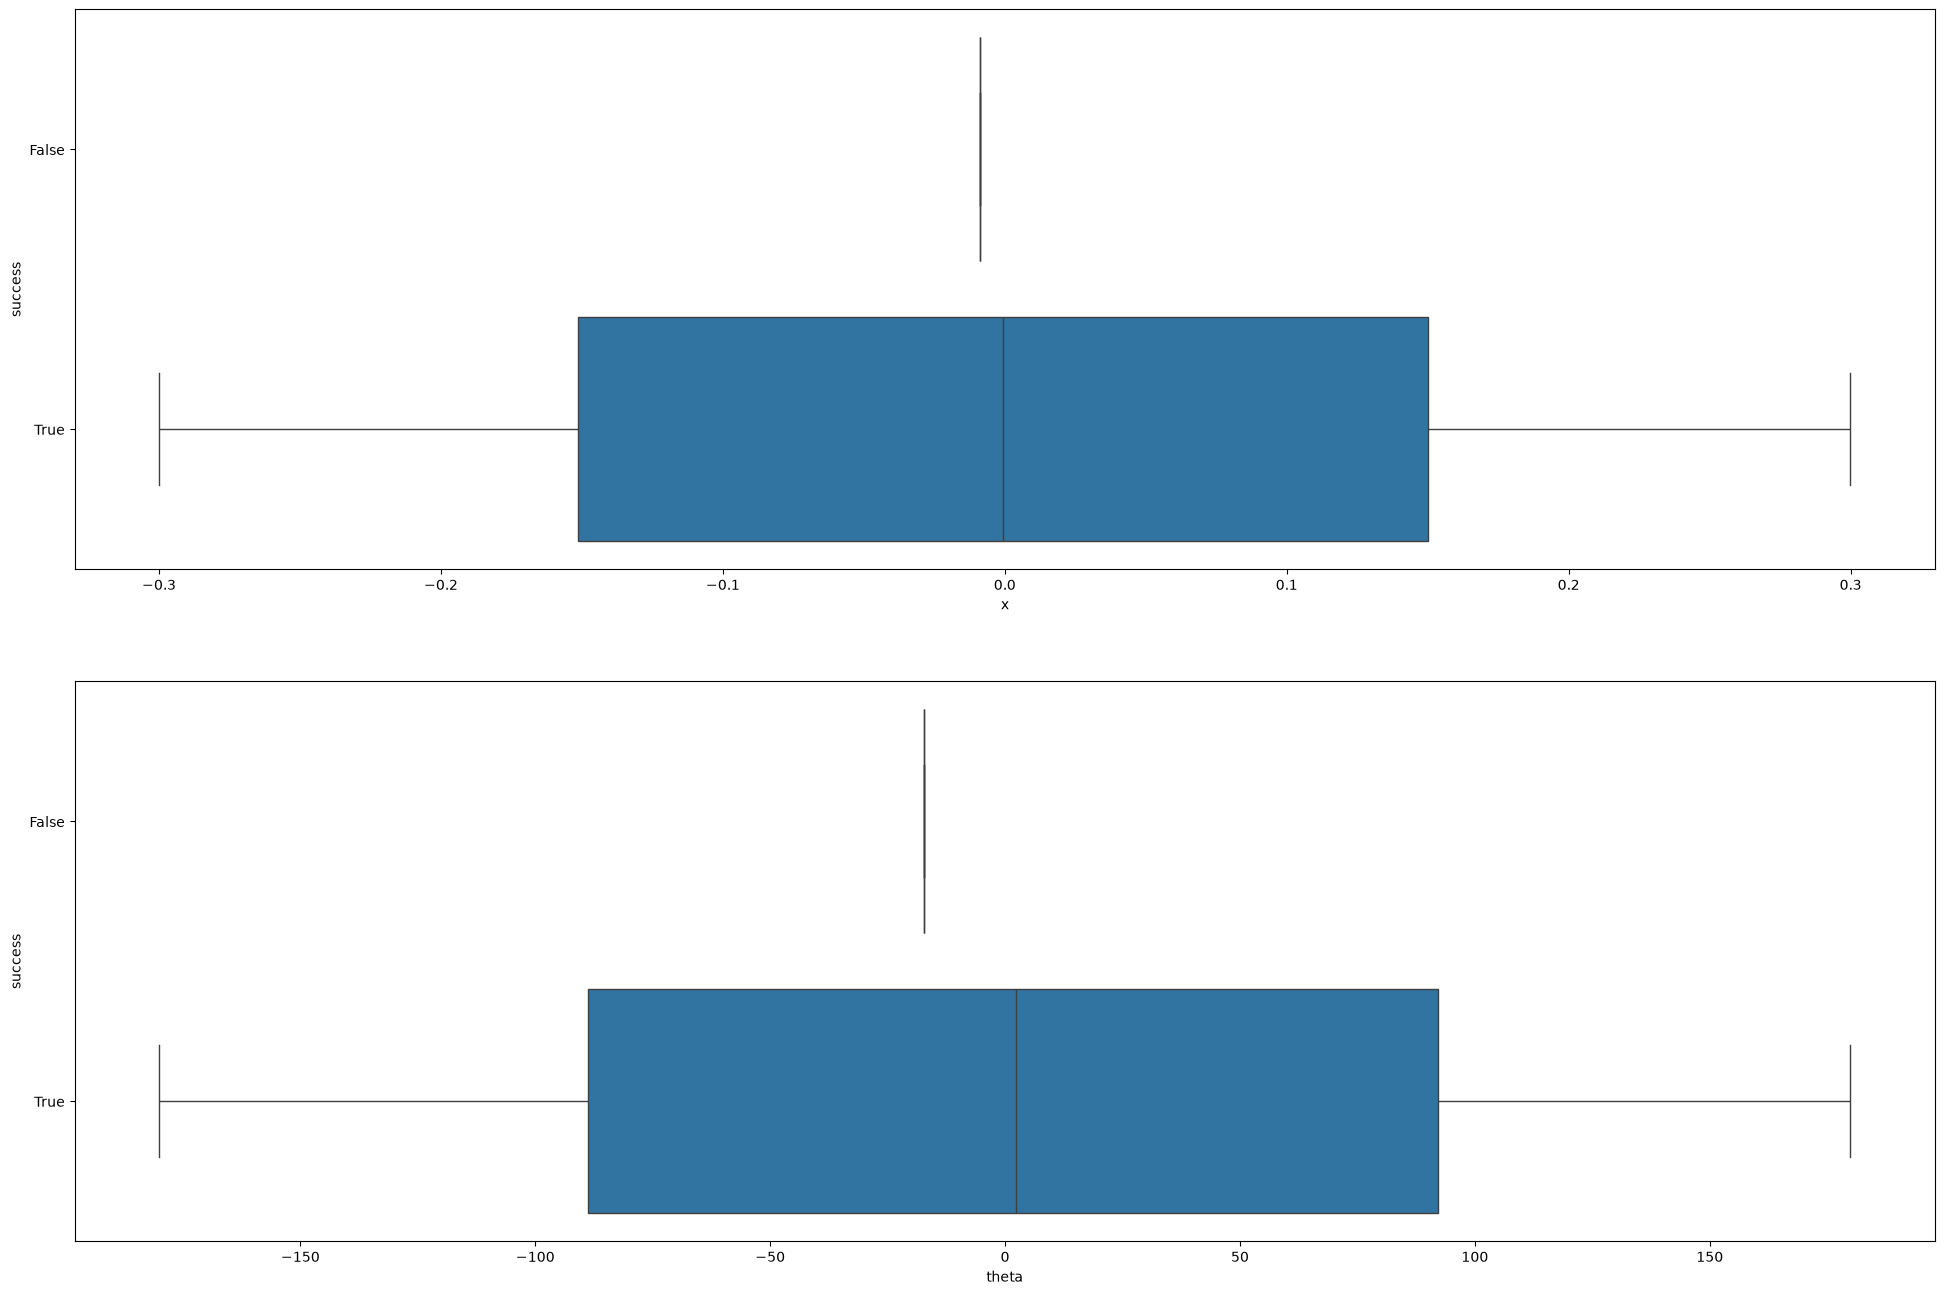

In [136]:
f, axes = plt.subplots(2, 1, figsize=(24, 16))
sb.boxplot(x = "x", y = "success", data = batch_results, orient = "h", ax=axes[0])
sb.boxplot(x = "theta", y = "success", data = batch_results, orient = "h", ax=axes[1])

In [137]:
last_reset_states = pd.read_csv("../results/last_reset_states.csv")
last_reset_states.head()

,success,x,v,theta,omega,energy
0,True,0.007895,-0.007100,0.007010,-0.174192,-1.470953
1,True,-0.009778,0.024788,0.003800,-0.062169,-1.471423
2,True,-0.004870,0.005361,-0.006617,0.167852,-1.470996
3,True,-0.009806,0.025144,0.008505,-0.053396,-1.471397
4,True,-0.009809,0.021788,0.005283,0.015065,-1.471476


In [138]:
last_reset_states_clean = last_reset_states[last_reset_states["energy"] < 0]
last_reset_states_clean

,success,x,v,theta,omega,energy
0,True,0.007895,-0.007100,0.007010,-0.174192,-1.470953
1,True,-0.009778,0.024788,0.003800,-0.062169,-1.471423
2,True,-0.004870,0.005361,-0.006617,0.167852,-1.470996
3,True,-0.009806,0.025144,0.008505,-0.053396,-1.471397
4,True,-0.009809,0.021788,0.005283,0.015065,-1.471476
...,...,...,...,...,...,...
9995,True,-0.009867,0.028743,0.006541,0.009905,-1.471467
9996,True,-0.009812,0.035497,0.009582,-0.013319,-1.471428
9997,True,-0.009942,0.036753,0.006939,0.052921,-1.471423
9998,True,-0.004793,0.023399,0.011100,-0.157464,-1.470986


<Axes: xlabel='energy', ylabel='success'>

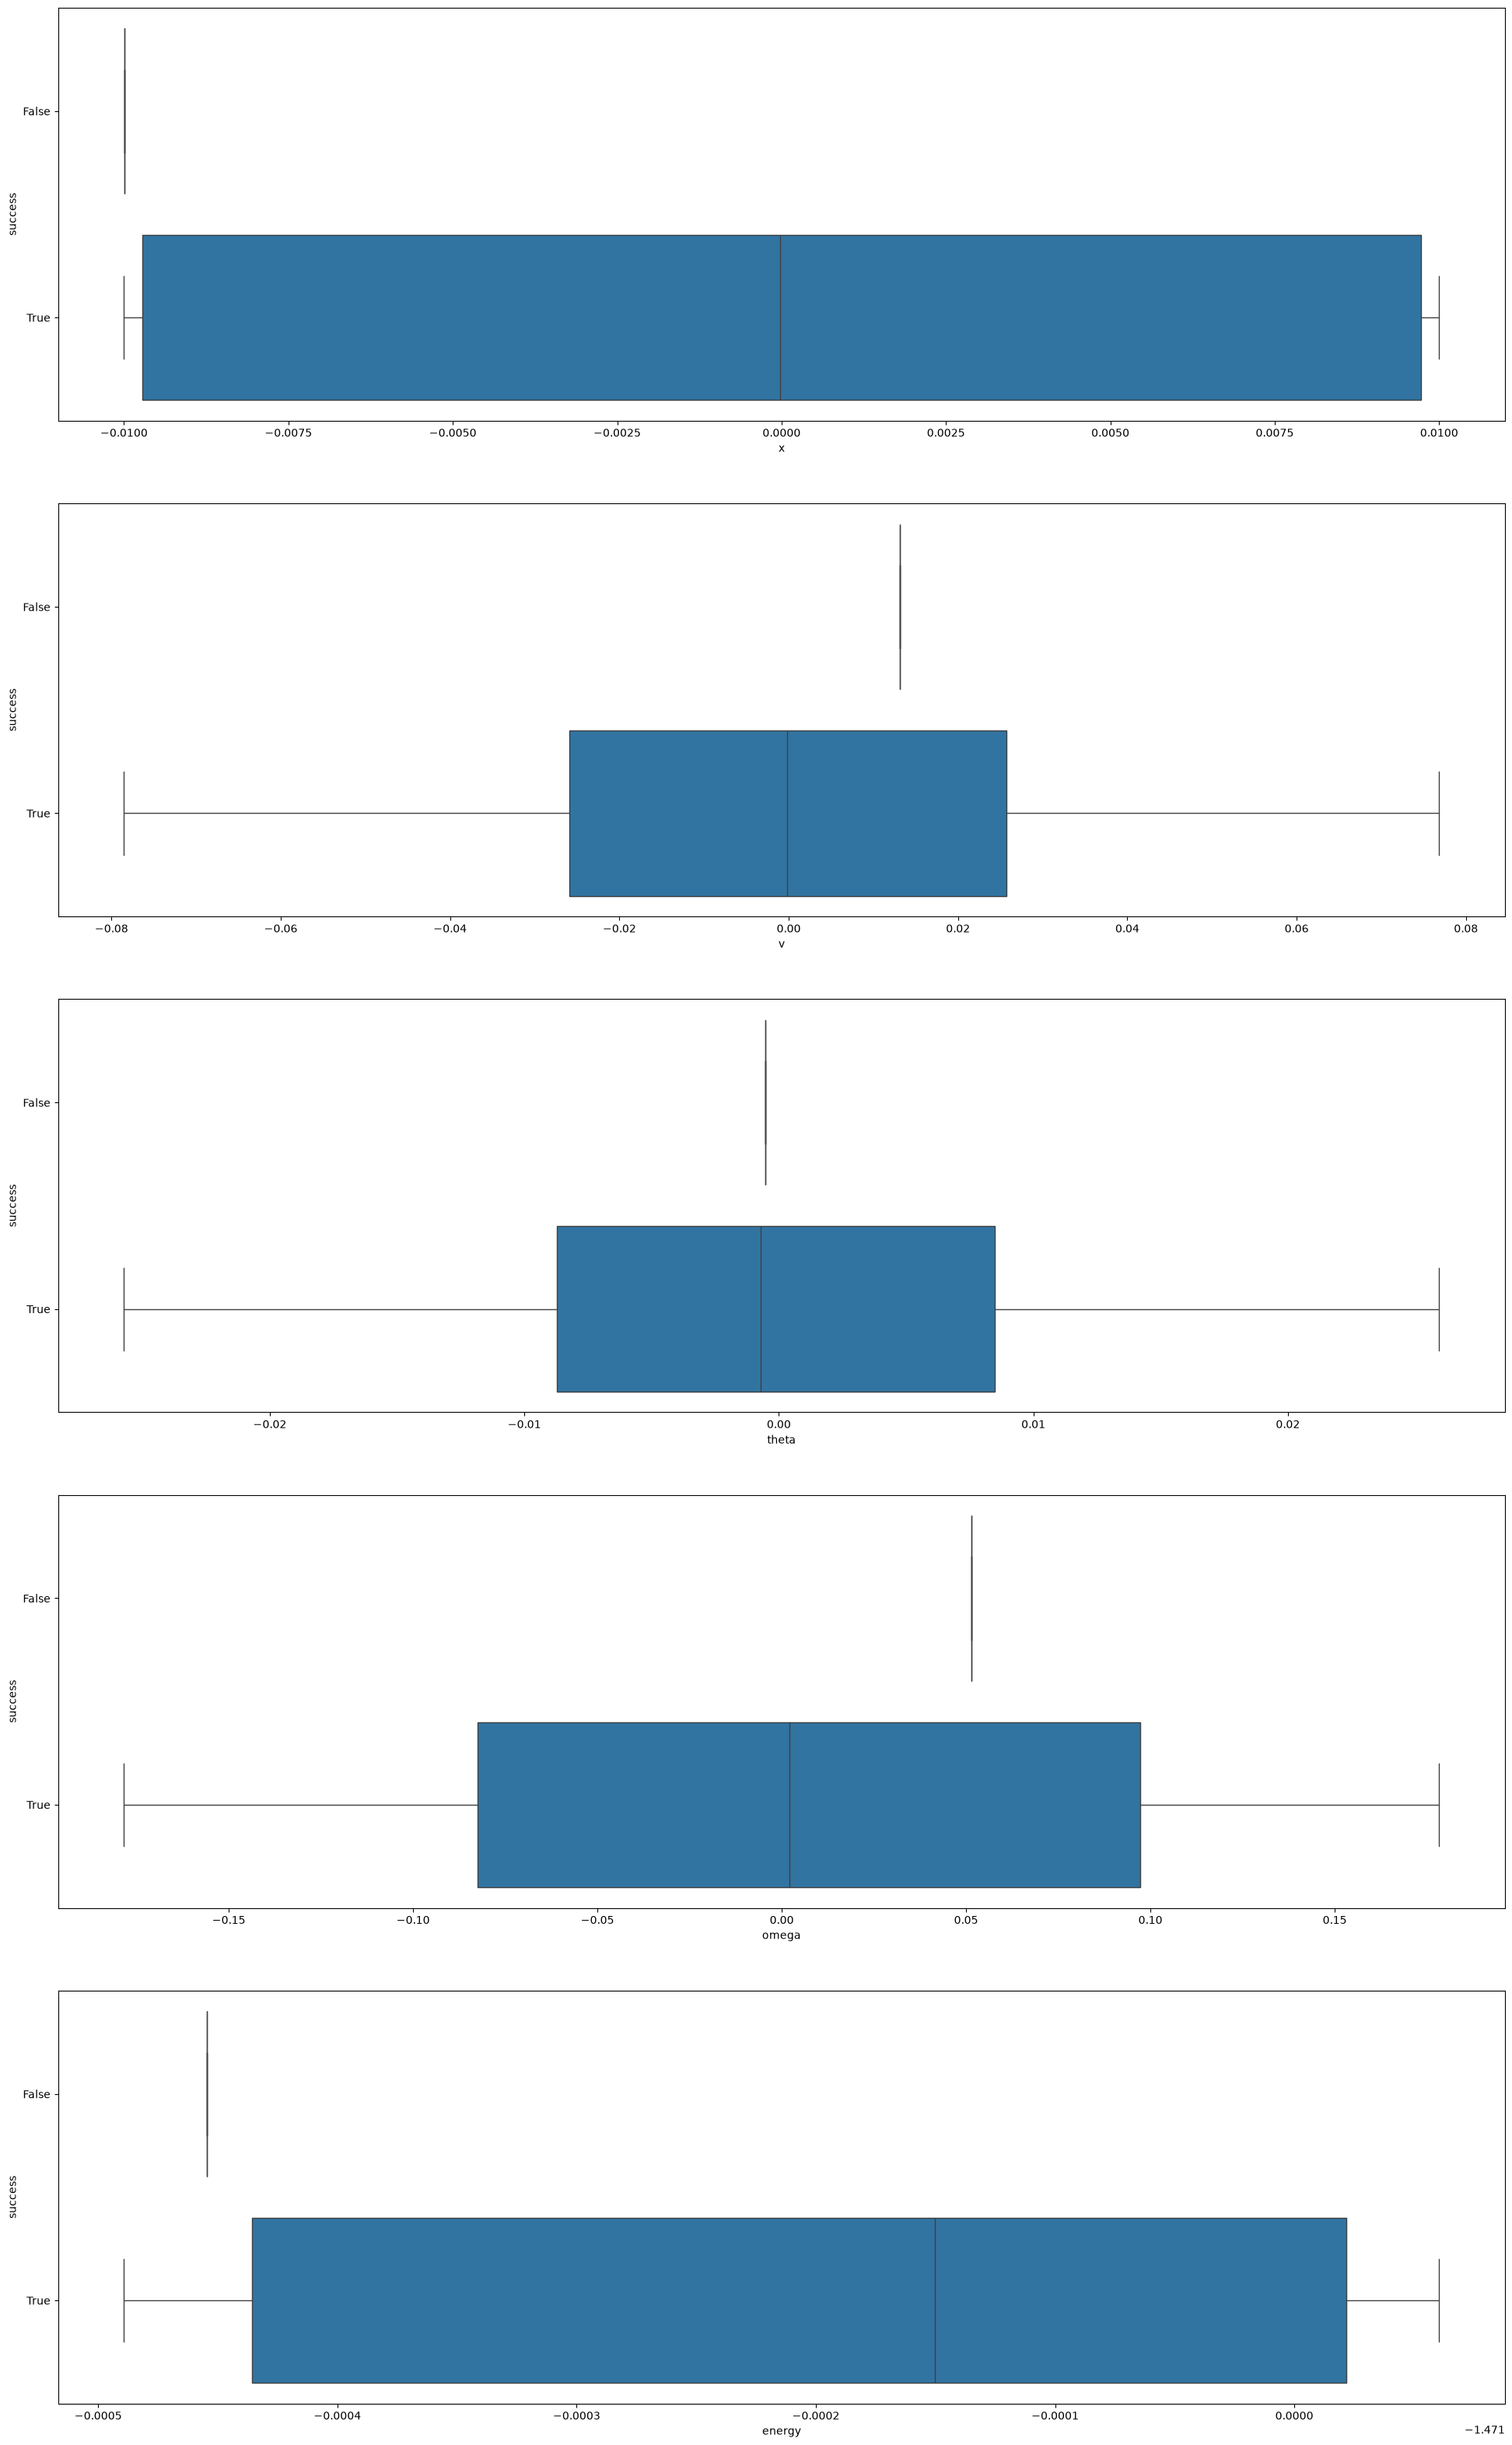

In [139]:
f, axes = plt.subplots(5, 1, figsize=(24, 40))
sb.boxplot(x = "x", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[0])
sb.boxplot(x = "v", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[1])
sb.boxplot(x = "theta", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[2])
sb.boxplot(x = "omega", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[3])
sb.boxplot(x = "energy", y = "success", data = last_reset_states_clean, orient = "h", ax=axes[4])

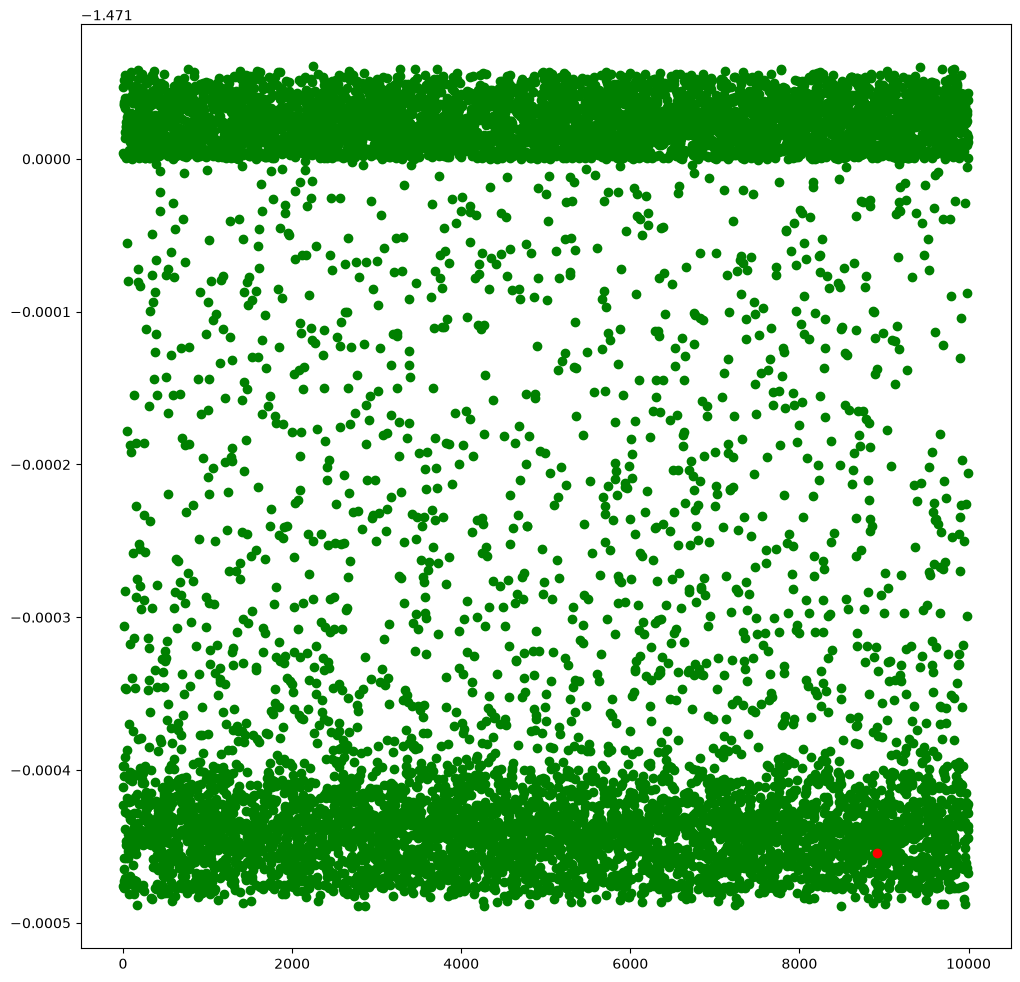

In [140]:
f = plt.figure(figsize=(12, 12))
plt.scatter(last_reset_states_clean[last_reset_states_clean["success"]==True].index, last_reset_states_clean[last_reset_states_clean["success"]==True]["energy"], color="green")
plt.scatter(last_reset_states_clean[last_reset_states_clean["success"]==False].index, last_reset_states_clean[last_reset_states_clean["success"]==False]["energy"], color="red")
